# Dealing with Outliers

Sometimes outliers can mess up an analysis; you usually don't want a handful of data points to skew the overall results. Let's revisit our example of income data, with some random billionaire thrown in:

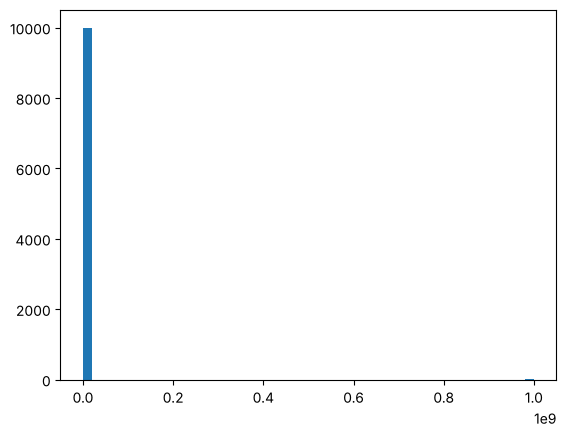

In [1]:
%matplotlib inline
import numpy as np

incomes = np.random.normal(27000, 15000, 10000)
incomes = np.append(incomes, [1000000000])

import matplotlib.pyplot as plt
plt.hist(incomes, 50)
plt.show()

That's not very helpful to look at. One billionaire ended up squeezing everybody else into a single line in my histogram. Plus it skewed the mean income significantly:

In [2]:
incomes.mean()

np.float64(126824.12178689639)

It's important to dig into what is causing your outliers, and understand where they are coming from. You also need to think about whether removing them is a valid thing to do, given the spirit of what it is you're trying to analyze. If I know I want to understand more about the incomes of "typical Americans", filtering out billionaires seems like a legitimate thing to do.

Here's something a little more robust than filtering out billionaires - it filters out anything beyond two standard deviations of the median value in the data set:

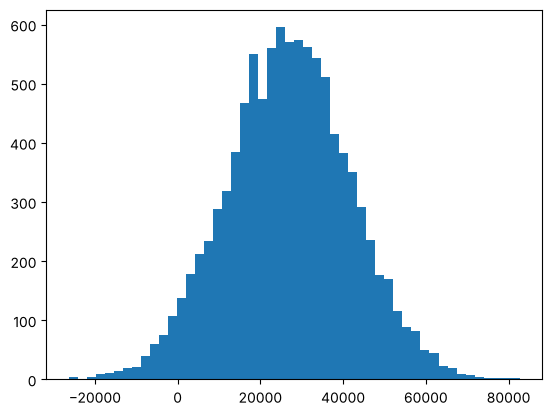

In [3]:
def reject_outliers(data):
    u = np.median(data)
    s = np.std(data)
    filtered = [e for e in data if (u - 2 * s < e < u + 2 * s)]
    return filtered

filtered = reject_outliers(incomes)

plt.hist(filtered, 50)
plt.show()

That looks better. And, our mean is more, well, meangingful now as well:

In [4]:
np.mean(filtered)

np.float64(26836.80419907507)

## Activity

Instead of a single outlier, add several randomly-generated outliers to the data. Experiment with different values of the multiple of the standard deviation to identify outliers, and see what effect it has on the final results.

Moyenne avec outliers : 820225.49
Médiane avec outliers : 26643.52


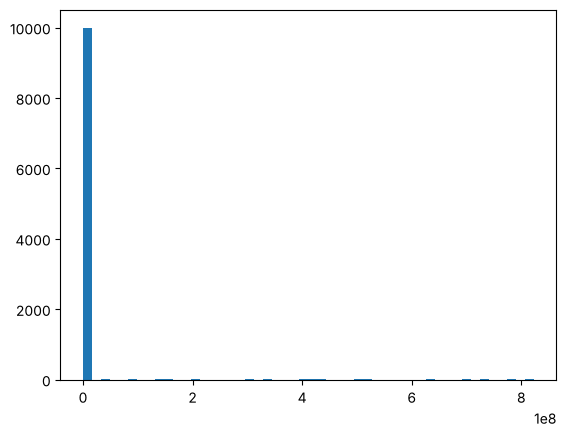

In [5]:
np.random.seed(0)
incomes = np.random.normal(27000, 15000, 10000)

# plusieurs outliers générés aléatoirement (entre 500 000 et 1 milliard)
outliers = np.random.uniform(500000, 1000000000, 20)
incomes = np.append(incomes, outliers)

print("Moyenne avec outliers :", round(incomes.mean(), 2))
print("Médiane avec outliers :", round(np.median(incomes), 2))

plt.hist(incomes, 50)
plt.show()

In [6]:
# on teste plusieurs multiples de l'écart-type
def reject_outliers2(data, k):
    u = np.median(data)
    s = np.std(data)
    return [e for e in data if (u - k * s < e < u + k * s)]

for k in [0.5, 1, 2, 3, 5]:
    f = reject_outliers2(incomes, k)
    print("k =", k, "-> points gardés :", len(f), " moyenne :", round(np.mean(f), 2))

k = 0.5 -> points gardés : 10000  moyenne : 26723.49
k = 1 -> points gardés : 10000  moyenne : 26723.49
k = 2 -> points gardés : 10000  moyenne : 26723.49
k = 3 -> points gardés : 10001  moyenne : 31552.85
k = 5 -> points gardés : 10003  moyenne : 49602.5


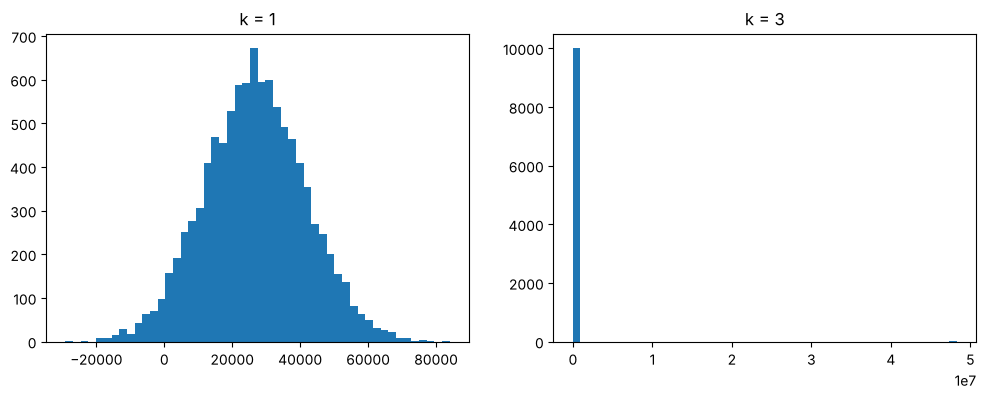

In [7]:
f1 = reject_outliers2(incomes, 1)
f3 = reject_outliers2(incomes, 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(f1, 50)
axes[0].set_title("k = 1")
axes[1].hist(f3, 50)
axes[1].set_title("k = 3")
plt.show()

Avec 20 outliers très grands, la moyenne passe de 27 000 environ à plus de 800 000 alors que la médiane reste proche de 26 600 : les outliers faussent complètement la moyenne.

En changeant le multiple k de l'écart-type, on voit que :
- avec k petit (0.5 à 2) tous les outliers sont éliminés et la moyenne revient à environ 26 700, ce qui est cohérent avec les données normales ;
- avec k = 3 puis k = 5 quelques outliers restent dans les données filtrées et la moyenne remonte (31 500 puis 49 600) ;
- le problème est que l'écart-type est lui-même calculé avec les outliers, donc il est très gonflé et le seuil devient trop large quand k augmente.

Le choix de k dépend donc des données : trop grand on garde des outliers, trop petit on risque de supprimer des vraies valeurs (sur des données sans outliers extrêmes, k = 1 supprimerait environ 30% des points).